In [12]:
import numpy as np
import baseflowx
import shutil

# 1. Load forcing and attributes data
forcing_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"
attr_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy"
save_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_LocalHYSEP_mmday.npy"

total_flow_array = np.load(forcing_path)  # Shape: (basins, time, vars)
area_array = np.load(attr_path)           # Shape: (basins, vars)

num_basins, num_times, num_vars = total_flow_array.shape
baseflow_mm_results = np.empty((num_basins, num_times))

for i in range(num_basins):
    Q_cfs = total_flow_array[i, :, 12]
    area = area_array[i, 11]  # Drainage area 
    
    # If your area is in km2, convert to m2. (Uncomment line below if area is in km2)
    area_m2 = area * 1e6
    # area_m2 = area  # Assuming area is already in m2. Adjust if it's in km2.

    # Calculate scalar turning point interval for HYSEP
    scalar_b_lh = int(2.0 * np.ceil(2.08 * (area ** 0.2)))
    b_LH_array = np.full_like(Q_cfs, fill_value=scalar_b_lh, dtype=float)
    
    # Run Local Minimum method (returns baseflow in cfs)
    baseflow_cfs = baseflowx.local(Q_cfs, b_LH=b_LH_array, area=area)
    
    # Convert cfs to mm/day:
    # 1 cfs = 0.028316847 m^3/s -> * 86400 s/day = m^3/day
    # (m^3/day / area_m2) = meters/day -> * 1000 = mm/day
    conversion_factor = (0.3048 ** 3) * 86400 * 1000 / area_m2
    baseflow_mm_results[i, :] = baseflow_cfs * conversion_factor

# 2. Add the new baseflow time-series variable to the forcing array
# Expand dimensions to match (basins, time, 1) so it can be concatenated along the vars axis (axis=2)
baseflow_expanded = np.expand_dims(baseflow_mm_results, axis=-1)
updated_forcing_array = np.concatenate([total_flow_array, baseflow_expanded], axis=2)

# 3. Save the updated array
np.save(save_path, updated_forcing_array)
forcing_json= "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_eckhardt_mmday_name.json"
shutil.copy(forcing_json, "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_LocalHYSEP_mmday_name.json")

print("Baseflow separation and unit conversion completed.")
print("Original forcing shape:", total_flow_array.shape)
print("Updated forcing shape (with baseflow added):", updated_forcing_array.shape)
print("Saved to:", save_path)

Baseflow separation and unit conversion completed.
Original forcing shape: (671, 12784, 15)
Updated forcing shape (with baseflow added): (671, 12784, 16)
Saved to: /scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_LocalHYSEP_mmday.npy


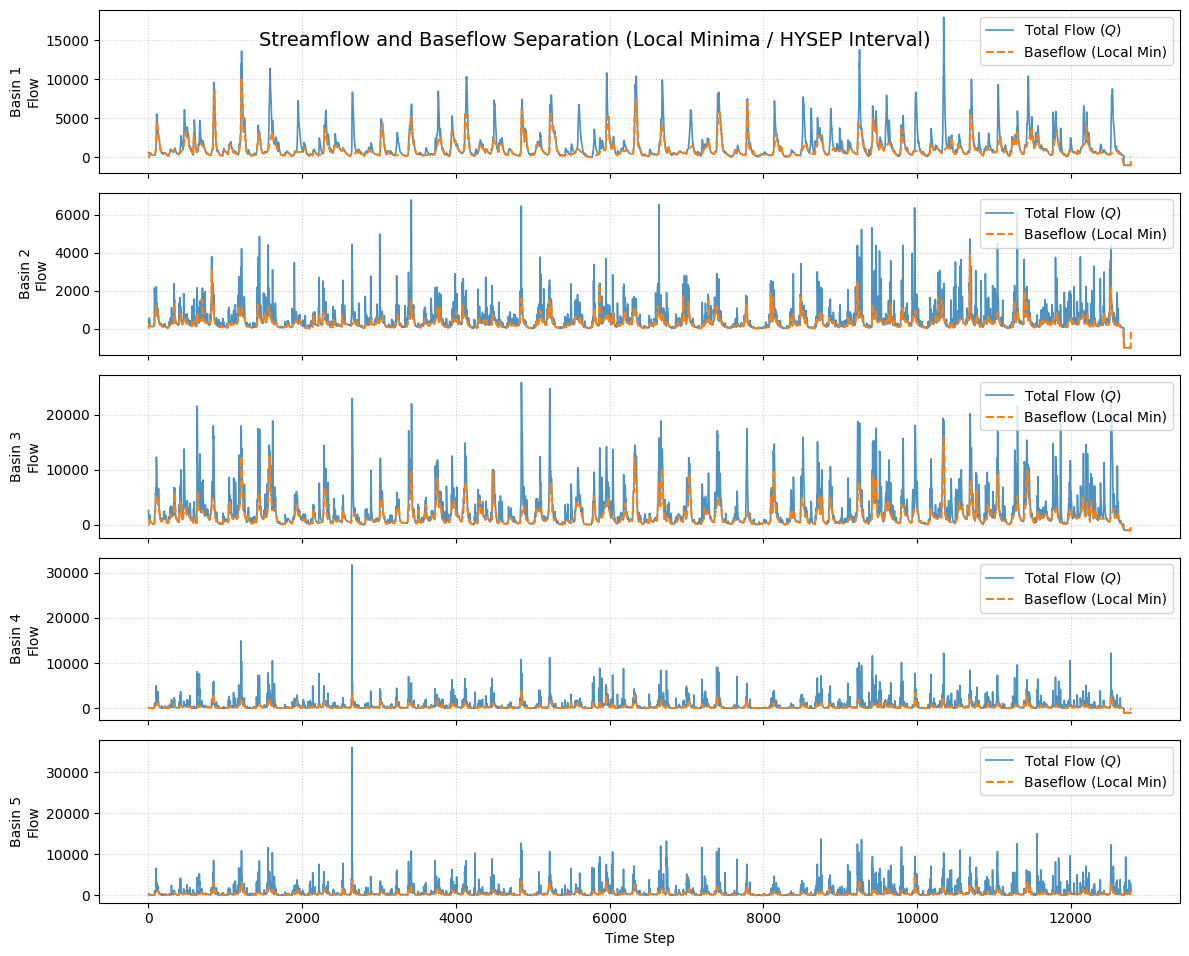

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import baseflowx

# Assuming your arrays are already loaded:
# total_flow_array shape: (basins, time, vars) -> flow at index 12
# area_array shape: (basins, vars) -> area at index 11

num_basins, num_times, num_vars = total_flow_array.shape
baseflow_results = np.empty((num_basins, num_times))

# 1. Compute baseflow for all basins using the Local Minima method + HYSEP interval
for i in range(num_basins):
    Q = total_flow_array[i, :, 12]
    area = area_array[i, 11]
    
    # Calculate scalar interval and broadcast it to match the 1D time array length
    scalar_b_lh = int(2.0 * np.ceil(2.08 * (area ** 0.2)))
    b_LH_array = np.full_like(Q, fill_value=scalar_b_lh, dtype=float)
    
    # Run Local Minima method
    baseflow_results[i, :] = baseflowx.local(Q, b_LH=b_LH_array, area=area)

# 2. Plotting time series for the first 5 basins
fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)

# Select up to 5 basins to plot
num_plots = min(5, num_basins)

for i in range(num_plots):
    ax = axes[i]
    time_steps = np.arange(num_times)
    
    # Plot Total Flow (Q) and Baseflow
    ax.plot(time_steps, total_flow_array[i, :, 12], label='Total Flow ($Q$)', color='tab:blue', alpha=0.8, linewidth=1.2)
    ax.plot(time_steps, baseflow_results[i, :], label='Baseflow (Local Min)', color='tab:orange', linestyle='--', linewidth=1.5)
    
    ax.set_ylabel(f'Basin {i+1}\nFlow')
    ax.legend(loc='upper right', frameon=True)
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel('Time Step')
fig.suptitle('Streamflow and Baseflow Separation (Local Minima / HYSEP Interval)', fontsize=14, y=0.93)

plt.tight_layout()
plt.show()

In [13]:
import numpy as np
f1= np.load("/scratch/data/PUR_DATA/test/Region_1/daymet_19800101_20141231_forcing_671_LocalHYSEP_mmday.npy")
f2= np.load("/scratch/data/PUR_DATA/test/Region_1/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")

In [14]:
f1[0,:,-1]

array([ 0.06824479,  0.06824479,  0.06824479, ..., -4.26103377,
        0.06824479,  0.06824479], shape=(12784,))

In [ ]:
f2[0,:,-1]

array([1.05842036, 1.051798  , 1.04077773, ...,        nan,        nan,
              nan], shape=(12784,))

: 